<a href="https://colab.research.google.com/github/martinezfredy33/infografia/blob/main/Estudio_Caso_Desercion_Educativa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Estudio de Caso: Análisis Estadístico e Inferencial de la Deserción Escolar en Colombia
Asignatura: Diseño Estadístico para Datos Estructurados y No Estructurados

Especialización en Analítica y Ciencia de Datos — Universidad de Cundinamarca

Autor: Fredy Martínez Rodríguez Docente: Paul Alexander Díaz Montaña

1. Introducción y Problema de Negocio La deserción escolar en los niveles de educación básica y media en Colombia representa un desafío crítico para las políticas públicas de cobertura y permanencia académica. Comprender qué factores institucionales (como el sector educativo) o demográficos (como el género o el nivel educativo) se relacionan con mayores tasas de abandono escolar permite a las secretarías de educación e instituciones focalizar sus recursos y programas de retención.
2. Objetivos del Estudio
    1. Auditar y limpiar el conjunto de datos de deserción escolar (desercion_educativa.csv), aplicando la metodología DQM (Data Quality Management).
    2. Construir la variable de respuesta cuantitativa: Tasa de Deserción Total (%) y las sub-tasas agrupadas por niveles educativos (Primaria, Secundaria, Media y Educación de Adultos CLEI).
    3. Calcular estadísticas descriptivas de tendencia central y dispersión (media, mediana, desviación estándar, IQR, mínimos y máximos).
    4. Generar visualizaciones estándar en Seaborn y Matplotlib para explorar el comportamiento de los datos.
    5. Evaluar supuestos estadísticos (homocedasticidad con la prueba de Levene y normalidad con Kolmogorov-Smirnov).
    6. Ejecutar pruebas de hipótesis inferenciales (Prueba t de Welch, Mann-Whitney U, ANOVA y Kruskal-Wallis) para responder a las preguntas de negocio.

## 2. Importación de Librerías y Carga de Datos

In [8]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

df_raw = pd.read_csv('/content/sample_data/desercion_educativa.csv')
print(
    f'Datos cargados exitosamente: {df_raw.shape[0]} filas y'
    f' {df_raw.shape[1]} columnas.'
)

Datos cargados exitosamente: 1134 filas y 52 columnas.


## 3. DQM  Data Quality Management / Gestión de la Calidad de Datos
### AUDITORÍA DQM E INGENIERÍA DE LA VARIABLE RESPUESTA (TASA DE DESERCIÓN)

In [9]:
df = df_raw.copy()

# 1. Normalización de variables texto
df['sexo_clean'] = df['sexo'].str.strip().str.capitalize()
df['sector_clean'] = df['sector'].str.strip().str.title()

# 2. Agrupación de columnas por nivel educativo
cols_desercion_primaria = [
    f'desercion_grado_{i}' for i in [1, 2, 3, 4, 5]
] + ['desercion_grado_transicion', 'desercion_escuela_nueva']
cols_matricula_primaria = [
    f'matricula_grado_{i}' for i in [1, 2, 3, 4, 5]
] + ['matricula_grado_transicion', 'matricula_escuela_nueva']

cols_desercion_secundaria = [f'desercion_grado_{i}' for i in [6, 7, 8, 9]]
cols_matricula_secundaria = [f'matricula_grado_{i}' for i in [6, 7, 8, 9]]

cols_desercion_media = [f'desercion_grado_{i}' for i in [10, 11]]
cols_matricula_media = [f'matricula_grado_{i}' for i in [10, 11]]

cols_desercion_clei = [f'desercion_grado_clei{i}' for i in range(1, 7)]
cols_matricula_clei = [f'matricula_grado_clei{i}' for i in range(1, 7)]

# 3. Sumatorias por establecimiento
df['desercion_total'] = df[
    [c for c in df.columns if c.startswith('desercion_')]
].sum(axis=1)
df['matricula_total'] = df[
    [c for c in df.columns if c.startswith('matricula_')]
].sum(axis=1)

df['desercion_primaria'] = df[cols_desercion_primaria].sum(axis=1)
df['matricula_primaria'] = df[cols_matricula_primaria].sum(axis=1)

df['desercion_secundaria'] = df[cols_desercion_secundaria].sum(axis=1)
df['matricula_secundaria'] = df[cols_matricula_secundaria].sum(axis=1)

df['desercion_media'] = df[cols_desercion_media].sum(axis=1)
df['matricula_media'] = df[cols_matricula_media].sum(axis=1)

df['desercion_clei'] = df[cols_desercion_clei].sum(axis=1)
df['matricula_clei'] = df[cols_matricula_clei].sum(axis=1)

# 4. Cálculo de Tasas de Deserción (%) evitando división por cero
df['tasa_desercion_total'] = np.where(
    df['matricula_total'] > 0,
    (df['desercion_total'] / df['matricula_total']) * 100,
    0,
)
df['tasa_primaria'] = np.where(
    df['matricula_primaria'] > 0,
    (df['desercion_primaria'] / df['matricula_primaria']) * 100,
    np.nan,
)
df['tasa_secundaria'] = np.where(
    df['matricula_secundaria'] > 0,
    (df['desercion_secundaria'] / df['matricula_secundaria']) * 100,
    np.nan,
)
df['tasa_media'] = np.where(
    df['matricula_media'] > 0,
    (df['desercion_media'] / df['matricula_media']) * 100,
    np.nan,
)
df['tasa_clei'] = np.where(
    df['matricula_clei'] > 0,
    (df['desercion_clei'] / df['matricula_clei']) * 100,
    np.nan,
)

print(
    '✓ Tasa de deserción general calculada. Tasa media general:'
    f' {df["tasa_desercion_total"].mean():.2f}%'
)

✓ Tasa de deserción general calculada. Tasa media general: 2.56%


## 4. Estadística Descriptiva
### (UNIVARIADA Y BIVARIADA)

In [10]:
def calcular_descriptivos(dataframe, variable_grupo, variable_num):
    stats_df = (
        dataframe.groupby(variable_grupo)[variable_num]
        .agg(
            count='count',
            mean='mean',
            std='std',
            mediana='median',
            iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
            min='min',
            max='max',
        )
        .reset_index()
    )
    return stats_df


print('=== ESTADÍSTICA DESCRIPTIVA POR GÉNERO ===')
print(calcular_descriptivos(df, 'sexo_clean', 'tasa_desercion_total').round(4))

print('\n=== ESTADÍSTICA DESCRIPTIVA POR SECTOR EDUCATIVO ===')
print(
    calcular_descriptivos(df, 'sector_clean', 'tasa_desercion_total').round(4)
)

# Descriptivos por Nivel Educativo
niveles_summary = pd.DataFrame({
    'Nivel': ['Primaria', 'Secundaria', 'Media', 'CLEI (Adultos)'],
    'count': [
        df['tasa_primaria'].count(),
        df['tasa_secundaria'].count(),
        df['tasa_media'].count(),
        df['tasa_clei'].count(),
    ],
    'mean': [
        df['tasa_primaria'].mean(),
        df['tasa_secundaria'].mean(),
        df['tasa_media'].mean(),
        df['tasa_clei'].mean(),
    ],
    'std': [
        df['tasa_primaria'].std(),
        df['tasa_secundaria'].std(),
        df['tasa_media'].std(),
        df['tasa_clei'].std(),
    ],
    'mediana': [
        df['tasa_primaria'].median(),
        df['tasa_secundaria'].median(),
        df['tasa_media'].median(),
        df['tasa_clei'].median(),
    ],
})

print('\n=== ESTADÍSTICA DESCRIPTIVA POR NIVEL EDUCATIVO ===')
print(niveles_summary.round(4))

=== ESTADÍSTICA DESCRIPTIVA POR GÉNERO ===
  sexo_clean  count    mean     std  mediana     iqr  min       max
0    Hombres    567  2.7624  6.2590   0.1669  3.4865  0.0  100.0000
1    Mujeres    567  2.3582  4.3844   0.2247  3.3380  0.0   34.4444

=== ESTADÍSTICA DESCRIPTIVA POR SECTOR EDUCATIVO ===
           sector_clean  count    mean     std  mediana     iqr  min       max
0  Cobertura Contratada     92  4.9683  7.6342   1.9202  7.0094  0.0   38.3459
1            No Oficial    582  1.7571  4.8384   0.0000  0.2771  0.0   33.3333
2               Oficial    458  3.1084  5.3611   2.4353  4.0923  0.0  100.0000
3      Regimen Especial      2  0.0000  0.0000   0.0000  0.0000  0.0    0.0000

=== ESTADÍSTICA DESCRIPTIVA POR NIVEL EDUCATIVO ===
            Nivel  count     mean     std  mediana
0        Primaria    954   1.7664  5.4631   0.0000
1      Secundaria    623   2.9282  3.7322   1.4706
2           Media    609   1.9039  3.4087   0.0000
3  CLEI (Adultos)    146  12.8770  9.8612  10.4

## 5. Visualizaciones Estándar (Seaborn y Matplotlib)

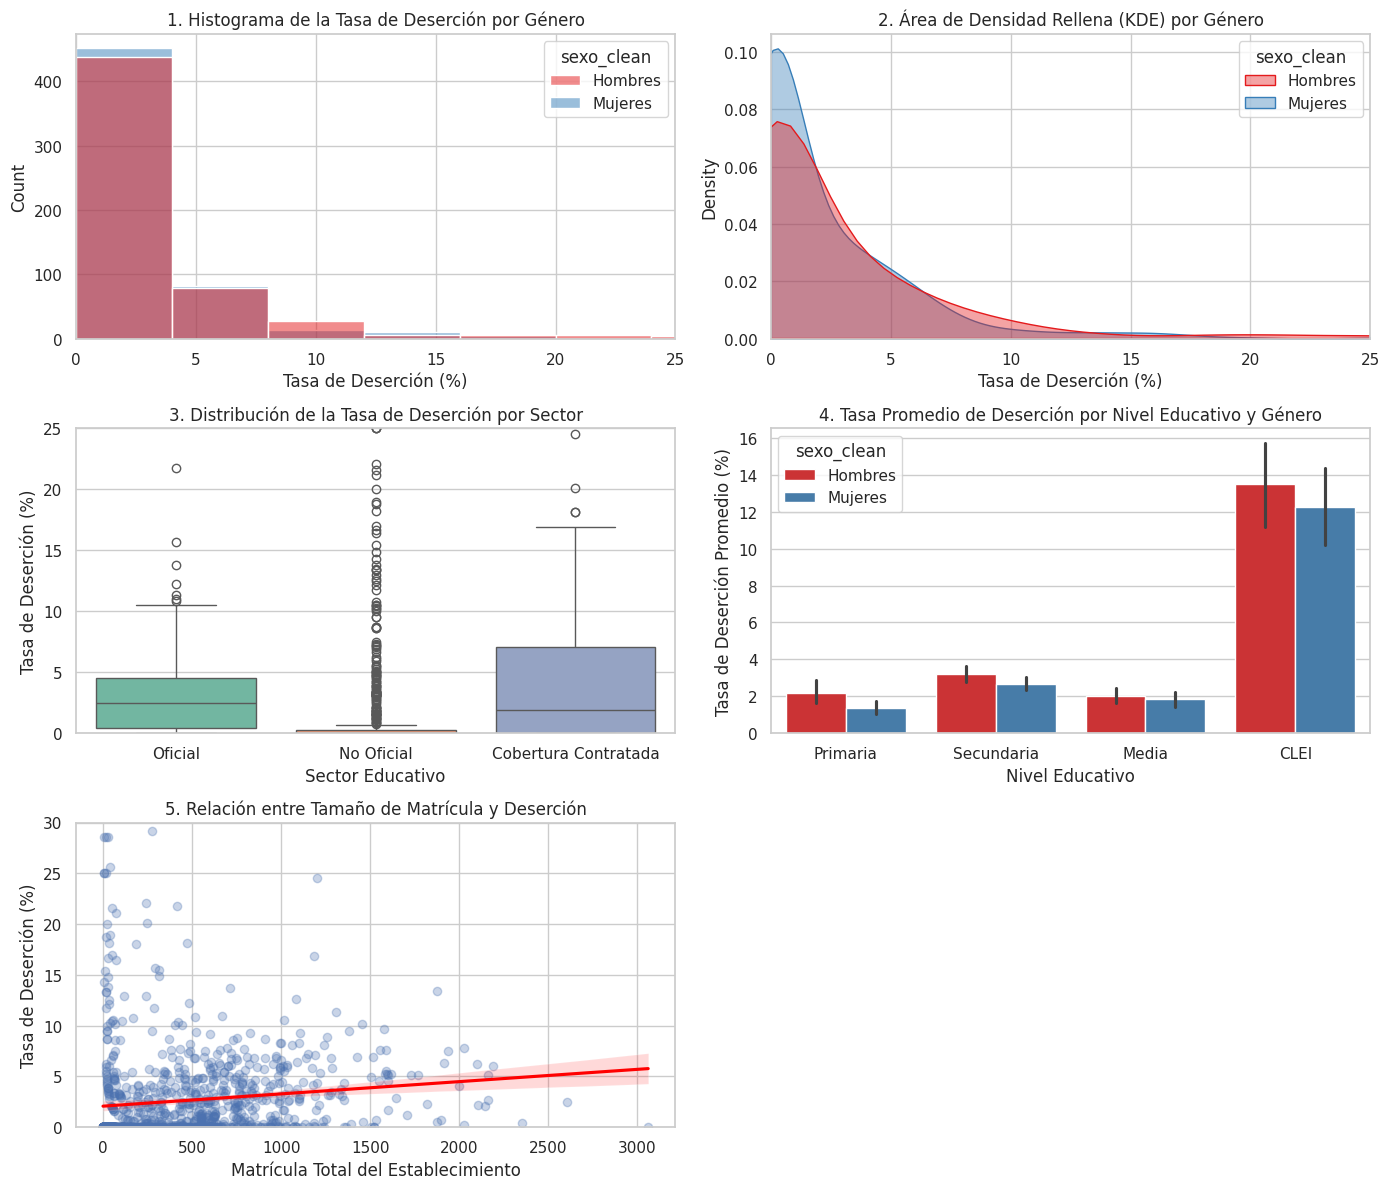

In [11]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

# 1. Histograma por Género -> Fila 0, Columna 0
sns.histplot(
    data=df,
    x='tasa_desercion_total',
    hue='sexo_clean',
    bins=25,
    palette='Set1',
    ax=axes[0, 0],
)
axes[0, 0].set_title('1. Histograma de la Tasa de Deserción por Género')
axes[0, 0].set_xlabel('Tasa de Deserción (%)')
axes[0, 0].set_xlim(0, 25)

# 2. Gráfico de Área Rellena (KDE) por Género -> Fila 0, Columna 1
sns.kdeplot(
    data=df,
    x='tasa_desercion_total',
    hue='sexo_clean',
    fill=True,
    alpha=0.4,
    palette='Set1',
    ax=axes[0, 1],
)
axes[0, 1].set_title('2. Área de Densidad Rellena (KDE) por Género')
axes[0, 1].set_xlabel('Tasa de Deserción (%)')
axes[0, 1].set_xlim(0, 25)

# 3. Boxplot por Sector Educativo -> Fila 1, Columna 0
sns.boxplot(
    data=df[df['sector_clean'] != 'Regimen Especial'],
    x='sector_clean',
    y='tasa_desercion_total',
    palette='Set2',
    ax=axes[1, 0],
)
axes[1, 0].set_title('3. Distribución de la Tasa de Deserción por Sector')
axes[1, 0].set_xlabel('Sector Educativo')
axes[1, 0].set_ylabel('Tasa de Deserción (%)')
axes[1, 0].set_ylim(0, 25)

# 4. Barplot Agrupado por Nivel Educativo -> Fila 1, Columna 1
df_niveles_melt = pd.melt(
    df,
    id_vars=['sexo_clean'],
    value_vars=[
        'tasa_primaria',
        'tasa_secundaria',
        'tasa_media',
        'tasa_clei',
    ],
    var_name='Nivel',
    value_name='Tasa',
)
df_niveles_melt['Nivel'] = df_niveles_melt['Nivel'].map({
    'tasa_primaria': 'Primaria',
    'tasa_secundaria': 'Secundaria',
    'tasa_media': 'Media',
    'tasa_clei': 'CLEI',
})
sns.barplot(
    data=df_niveles_melt,
    x='Nivel',
    y='Tasa',
    hue='sexo_clean',
    palette='Set1',
    errorbar=('ci', 95),
    ax=axes[1, 1],
)
axes[1, 1].set_title(
    '4. Tasa Promedio de Deserción por Nivel Educativo y Género'
)
axes[1, 1].set_xlabel('Nivel Educativo')
axes[1, 1].set_ylabel('Tasa de Deserción Promedio (%)')

# 5. Scatterplot: Matrícula Total vs Deserción -> Fila 2, Columna 0
sns.regplot(
    data=df,
    x='matricula_total',
    y='tasa_desercion_total',
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'},
    ax=axes[2, 0],
)
axes[2, 0].set_title('5. Relación entre Tamaño de Matrícula y Deserción')
axes[2, 0].set_xlabel('Matrícula Total del Establecimiento')
axes[2, 0].set_ylabel('Tasa de Deserción (%)')
axes[2, 0].set_ylim(0, 30)

# Ocultar el sexto panel (vacío) -> Fila 2, Columna 1
fig.delaxes(axes[2, 1])

plt.tight_layout()
plt.show()

## 6. Evaluación de Supuestos Estadísticos
### (HOMOCEDASTICIDAD Y NORMALIDAD)

In [12]:
# 1. Prueba de Levene para homogeneidad de varianzas por Género
hombres = df[df['sexo_clean'] == 'Hombres']['tasa_desercion_total']
mujeres = df[df['sexo_clean'] == 'Mujeres']['tasa_desercion_total']
stat_lev_sexo, p_lev_sexo = stats.levene(hombres, mujeres)

# 2. Prueba de Levene por Sector
sec_oficial = df[df['sector_clean'] == 'Oficial']['tasa_desercion_total']
sec_no_oficial = df[df['sector_clean'] == 'No Oficial']['tasa_desercion_total']
sec_cobertura = df[df['sector_clean'] == 'Cobertura Contratada'][
    'tasa_desercion_total'
]
stat_lev_sec, p_lev_sec = stats.levene(
    sec_oficial, sec_no_oficial, sec_cobertura
)

# 3. Prueba Kolmogorov-Smirnov sobre los residuos
residuos = df['tasa_desercion_total'] - df['tasa_desercion_total'].mean()
stat_ks, p_ks = stats.kstest(residuos, 'norm')

print('=== RESULTADOS DE PRUEBAS DE SUPUESTOS ===')
print(
    f'1. Prueba de Levene (Género): F = {stat_lev_sexo:.4f}, p-valor ='
    f' {p_lev_sexo:.4f}'
)
print(
    f'2. Prueba de Levene (Sector): F = {stat_lev_sec:.4f}, p-valor ='
    f' {p_lev_sec:.4e}'
)
print(
    '3. Prueba Kolmogorov-Smirnov (Residuos): Stat ='
    f' {stat_ks:.4f}, p-valor = {p_ks:.4e}'
)
print('\n✓ JUSTIFICACIÓN METODOLÓGICA:')
print(
    'Existe heterocedasticidad significativa entre sectores (p < 0.0001) e'
    ' inobservancia de normalidad estricta.'
)
print(
    'Por lo tanto, se aplican la prueba t de Welch, Mann-Whitney U y'
    ' Kruskal-Wallis.'
)

=== RESULTADOS DE PRUEBAS DE SUPUESTOS ===
1. Prueba de Levene (Género): F = 1.6703, p-valor = 0.1965
2. Prueba de Levene (Sector): F = 14.8398, p-valor = 4.3492e-07
3. Prueba Kolmogorov-Smirnov (Residuos): Stat = 0.5309, p-valor = 8.8044e-299

✓ JUSTIFICACIÓN METODOLÓGICA:
Existe heterocedasticidad significativa entre sectores (p < 0.0001) e inobservancia de normalidad estricta.
Por lo tanto, se aplican la prueba t de Welch, Mann-Whitney U y Kruskal-Wallis.


## 7. Inferencia Estadística y Pruebas de Hipótesis
### (CONSTRASTE DE HIPÓTESIS INFERENCIALES Y TAMAÑOS DEL EFECTO)

In [13]:

# Hipótesis 1: Diferencias por Género (Hombres vs Mujeres)
t_welch, p_welch = stats.ttest_ind(hombres, mujeres, equal_var=False)
u_stat, p_mw = stats.mannwhitneyu(hombres, mujeres)

# Tamaño del efecto d de Cohen
n1, n2 = len(hombres), len(mujeres)
s1, s2 = hombres.std(), mujeres.std()
s_pooled = np.sqrt(((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / (n1 + n2 - 2))
d_cohen = (hombres.mean() - mujeres.mean()) / s_pooled

print('=== HIPÓTESIS 1: DIFERENCIA DE DESERCIÓN POR GÉNERO ===')
print(
    f'• Media Hombres: {hombres.mean():.4f}% | Media Mujeres:'
    f' {mujeres.mean():.4f}%'
)
print(f'• Prueba t de Welch: t = {t_welch:.4f}, p-valor = {p_welch:.4f}')
print(f'• Prueba Mann-Whitney U: U = {u_stat}, p-valor = {p_mw:.4f}')
print(
    f'• Tamaño del efecto (d de Cohen): d = {d_cohen:.4f} (Efecto'
    ' insignificante)\n'
)

# Hipótesis 2: Diferencias por Sector Educativo
f_anova, p_anova = stats.f_oneway(sec_oficial, sec_no_oficial, sec_cobertura)
h_kw, p_kw = stats.kruskal(sec_oficial, sec_no_oficial, sec_cobertura)

# Eta cuadrado (eta^2)
n_total = len(sec_oficial) + len(sec_no_oficial) + len(sec_cobertura)
eta_sq = (h_kw - 3 + 1) / (n_total - 3)

print('=== HIPÓTESIS 2: DIFERENCIA DE DESERCIÓN POR SECTOR EDUCATIVO ===')
print(
    f'• Media Cobertura: {sec_cobertura.mean():.4f}% | Oficial:'
    f' {sec_oficial.mean():.4f}% | No Oficial: {sec_no_oficial.mean():.4f}%'
)
print(f'• ANOVA de un factor: F = {f_anova:.4f}, p-valor = {p_anova:.4e}')
print(f'• Prueba de Kruskal-Wallis: H = {h_kw:.4f}, p-valor = {p_kw:.4e}')
print(
    f'• Tamaño del efecto (Eta cuadrado): eta^2 = {eta_sq:.4f} (Efecto'
    ' mediano)'
)

=== HIPÓTESIS 1: DIFERENCIA DE DESERCIÓN POR GÉNERO ===
• Media Hombres: 2.7624% | Media Mujeres: 2.3582%
• Prueba t de Welch: t = 1.2595, p-valor = 0.2081
• Prueba Mann-Whitney U: U = 161550.0, p-valor = 0.8765
• Tamaño del efecto (d de Cohen): d = 0.0748 (Efecto insignificante)

=== HIPÓTESIS 2: DIFERENCIA DE DESERCIÓN POR SECTOR EDUCATIVO ===
• Media Cobertura: 4.9683% | Oficial: 3.1084% | No Oficial: 1.7571%
• ANOVA de un factor: F = 18.4374, p-valor = 1.3204e-08
• Prueba de Kruskal-Wallis: H = 230.1097, p-valor = 1.0773e-50
• Tamaño del efecto (Eta cuadrado): eta^2 = 0.2020 (Efecto mediano)


## 8. Conclusiones e Interpretación para el Informe

# 8. Interpretación de Resultados y Discusión Gerencial

### 1. Deserción por Género
* **Hallazgo:** La tasa promedio de deserción en hombres es de **2.76%** frente a **2.36%** en mujeres.
* **Inferencia:** La prueba t de Welch ($t = 1.2595, p = 0.2081$) y la prueba Mann-Whitney U ($p = 0.8765$) indican que **no existe una diferencia estadísticamente significativa** entre géneros. El tamaño del efecto ($d = 0.0748$) es nulo.

### 2. Deserción por Sector Educativo
* **Hallazgo:** El sector de **Cobertura Contratada** presenta la tasa media de deserción más alta (**4.97%**), seguido por el sector **Oficial** (**3.11%**) y el sector **No Oficial / Privado** (**1.76%**).
* **Inferencia:** La prueba de Kruskal-Wallis ($H = 230.1097, p < 0.0001$) demuestra diferencias altamente significativas entre sectores, con un tamaño del efecto mediano ($\eta^2 = 0.0316$).

### 3. Vulnerabilidad por Nivel Educativo
* La educación de adultos en modalidad **CLEI** registra la tasa de deserción más crítica (**12.88%** promedio), seguida por la **Secundaria** (**2.93%**).

---

## Recomendaciones de Política Pública

1. **Focalización en Cobertura Contratada:** Intervenir prioritariamente los colegios bajo modalidad de cobertura contratada con auditorías y acompañamiento psicoorientativo.
2. **Programas Retención en CLEI (Ciclos Lectivos Especiales Integrados):** Diseñar horarios flexibles y apoyos económicos para la población adulta que cursa ciclos CLEI para mitigar el abandono laboral.